---
authors:
  - name: Matthias Aengenheyster
    url: https://www.linkedin.com/in/matthias-aengenheyster-2a0ba5199/
---

# Day 20 · Hexagons — the grid, and nothing but the grid

<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

### #30DayMapChallenge 2026 · nextGEMS IFS + DestinE Climate DT · Map by Matthias Aengenheyster

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

A second take on hexagon day. [`day20_hexagons.ipynb`](day20_hexagons.ipynb) binned three
*different models* into H3 hexagons; useful, but it confounds resolution with model identity.
This notebook removes that confound entirely.

**HEALPix** — the grid km-scale climate models actually run on — is an equal-area
decomposition of the sphere, and its indexing is *nested*: the four children of a cell are
contiguous in memory. So coarsening by one zoom level is **exact**:

```python
coarse = fine.reshape(-1, 4).mean(axis=1)
```

No regridding, no interpolation, no area weights. One field, one operation, applied again and
again. The only thing that changes between panels is the grid.

**On the theme:** a HEALPix cell is *not* a hexagon — it is a curvilinear quadrilateral, and
on these maps it reads as a diamond. That is the price of exact equal area with exact nesting,
and the first figure draws one so you can see it. The third figure then bins the same field
into **H3 hexagons**, which are hexagons, and shows what that costs: they do not nest.

Three figures: the ladder, the same ladder on the operational projection, and the hexagons.

## Method

- **The field:** total precipitation rate from the **nextGEMS IFS cycle-3 `tco3999` run**
  (~2.8 km), on HEALPix **nside 2048 (zoom 11, 3.2 km cells)**, for **31 July 2020 19:00 UTC** —
  the hour of strongest Alpine convection in the run.
- **The ladder:** the global zoom-11 field is averaged 4 cells into 1, repeatedly, down to
  zoom 4. Each panel is the panel to its left, aggregated once.
- **Why the plain mean is correct:** HEALPix cells are equal-area, so an unweighted mean of
  four children *is* the area-weighted mean of their parent. Both notebooks assert the store
  really is nested before relying on it, and check that the global mean survives the ladder.
- **The quantity:** across the ladder the Alpine **maximum** collapses while the **mean over
  the same box** barely moves. Resolution does not change how much rain falls; it changes how
  concentrated the model is permitted to say it is.
- **Drawing:** cells are rasterised nearest-neighbour rather than drawn as polygons, after the
  `nnshow` recipe used across nextGEMS and DestinE. Each cell becomes a block of flat colour,
  so the tessellation draws itself and no cell outlines are needed — which is also the only way
  this stays fast with 50 million cells.
- **Climate DT:** the second figure runs the same ladder on the **operational DestinE
  projection**, from the 6.4 km HEALPix grid its output is published on down to roughly 200 km.
- **Hexagons:** the third figure re-bins the Alpine field into **H3** at three resolutions —
  6.5, 17 and 45 km across — which are hexagons, unlike HEALPix cells.

## Licence & attribution

**nextGEMS IFS cycle 3** is distributed through the **Digital Earths Global Hackathon**
catalogue — **public, no account required**. **DestinE Climate DT** phase 2 is available to
anyone with a [DestinE account](https://platform.destine.eu/) via **Polytope**; the local Zarr
used below is only a shortcut to the same data. Borders and coastlines are **Natural Earth**
(public domain).

`© ECMWF` · nextGEMS was funded by the European Union (Horizon 2020, grant 101003470).
Destination Earth is funded by the European Union and implemented by ECMWF, ESA and EUMETSAT.

## Tools

| Tool | Role |
|---|---|
| [`intake`](https://intake.readthedocs.io) | open the public hackathon catalogue |
| [`healpy`](https://healpy.readthedocs.io) | HEALPix pixel queries, cell boundaries, `ang2pix` for the raster |
| [`xarray`](https://docs.xarray.dev) · [`zarr`](https://zarr.readthedocs.io) · [`numpy`](https://numpy.org) | read the Zarr stores; the 4:1 aggregation itself is one `reshape` |
| [`cartopy`](https://scitools.org.uk/cartopy/docs/latest/) · [`matplotlib`](https://matplotlib.org) | equal-area projection, basemap, figure |

```bash
pip install intake==0.7.0 healpy xarray zarr numpy cartopy matplotlib
```

**Learn more:** [Digital Earths Global Hackathon catalogue](https://digital-earths-global-hackathon.github.io/catalog/) · [nextGEMS](https://nextgems-h2020.eu/) · [DestinE Climate DT](https://destine.ecmwf.int/) · [HEALPix](https://healpix.sourceforge.io/)

### Configuration

In [1]:
WHEN  = "2020-07-31T19:00"          # strongest Alpine convective hour in the run
BOX   = (5.0, 14.0, 44.0, 48.5)     # W, E, S, N - the Alps
ZOOMS = [11, 10, 9, 8, 7]           # the five map panels
ALL   = list(range(11, 3, -1))      # the full ladder, for the curve

# DestinE Climate DT, IFS-NEMO historical, high resolution (nside 1024 = zoom 10).
# On ECMWF systems this Zarr is a local shortcut; elsewhere use Polytope (see below).
CDT_ZARR = "/ec/ws2/project/destine/bridge/zarrs/phase2/IFS-NEMO/hist/clte/high/hourly/avg_tprate.zarr"
CDT_WHEN = "2012-09-10T02:00"       # an organised Alpine / Ligurian rain band
CDT_BOX  = (0.0, 20.0, 40.0, 52.0)  # central Europe - wide enough to still be a map at 200 km
CDT_ZF, CDT_ZC = 10, 5              # published zoom, and the bottom of its ladder

H3_PAD = (3.0, 16.0, 42.5, 50.0)    # pad the Alps box so edge hexagons are complete
H3_RES = [6, 5, 4]                  # ~6.5, ~17, ~45 km across

## Helpers

Four small functions do all the grid work. `box_pixels` and `descend` select cells;
`ladder` walks a selection up the tree; `raster` draws it.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, healpy as hp
import cartopy.crs as ccrs

def box_pixels(nside, w, e, s, n, pad=1.0):
    """Nested pixel ids whose centres fall inside the lon/lat box."""
    v = hp.ang2vec(np.array([w-pad, e+pad, e+pad, w-pad]),
                   np.array([s-pad, s-pad, n+pad, n+pad]), lonlat=True)
    pix = hp.query_polygon(nside, v, nest=True, inclusive=True)
    lo, la = hp.pix2ang(nside, pix, nest=True, lonlat=True)
    lo = np.where(lo > 180, lo - 360, lo)
    return np.sort(pix[(lo > w) & (lo < e) & (la > s) & (la < n)])

def raster(pix_ids, vals, nside, ax, nx=1500, ny=900):
    """Nearest-neighbour image of a sparse HEALPix selection, in the axes' projection.

    After Emma/nextGEMS `nnshow`: walk the pixels of the output image, ask which
    HEALPix cell each falls in, and colour it with that cell's value.  Cells show
    as blocks of flat colour, so the tessellation draws itself -- no cell outlines.
    """
    xl, yl = ax.get_xlim(), ax.get_ylim()
    X, Y = np.meshgrid(np.linspace(*xl, nx), np.linspace(*yl, ny))
    ll = ccrs.PlateCarree().transform_points(ax.projection, X, Y, np.zeros_like(X))
    ok = np.all(np.isfinite(ll), axis=-1)
    p = ll[ok].T
    pix = hp.ang2pix(nside, theta=p[0], phi=p[1], nest=True, lonlat=True)
    out = np.full(ll.shape[:-1], np.nan, "f4")
    if pix_ids is None:                       # vals is the whole sphere
        out[ok] = vals[pix]
    else:                                     # vals covers a subset of cells
        j = np.searchsorted(pix_ids, pix)
        hit = pix_ids[np.clip(j, 0, pix_ids.size - 1)] == pix
        tmp = np.full(pix.size, np.nan, "f4")
        tmp[hit] = vals[j[hit]]
        out[ok] = tmp
    return out, (xl[0], xl[1], yl[0], yl[1])

def descend(pix_coarse, z_coarse, z_fine):
    """Every descendant of a set of cells, z_coarse -> z_fine.  Nested indexing
    means cell p at one level owns 4p..4p+3 at the next, so the children of a
    sorted selection come out sorted and sibling-contiguous."""
    f = 4 ** (z_fine - z_coarse)
    return (pix_coarse[:, None].astype("i8") * f + np.arange(f)).ravel()

def ladder(pix, val, z_fine, z_coarse):
    """Walk a sibling-contiguous selection back up the tree.  Each step is one
    reshape -- exact, equal-area, no interpolation, no healpy call."""
    out = {z_fine: (pix, val)}
    for z in range(z_fine - 1, z_coarse - 1, -1):
        pix = pix.reshape(-1, 4)[:, 0] // 4
        val = val.reshape(-1, 4).mean(axis=1)
        out[z] = (pix, val)
    return out

def cell_km(z):
    return np.sqrt(4 * np.pi * 6371.0 ** 2 / (12 * 4 ** z))

### Look

Dry cells and off-grid pixels stay transparent so the land/sea wash shows through, and
coastlines are drawn last in ink with a pale halo — legible over both the dry background and
the darkest rain.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import BoundaryNorm, ListedColormap

INK, MUT, ACC, CDT = "#1d2230", "#6b7280", "#2c6fb3", "#0f766e"
SEA, LAND, EDGE = "#dde5ea", "#f3f1ec", "#c9ccd2"
PC = ccrs.PlateCarree()

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

BINS = [0.1, 0.5, 1, 2, 5, 10, 25, 60, 160]
_c = plt.get_cmap("YlGnBu")(np.linspace(0.20, 1.0, len(BINS) - 1))
CMAP = ListedColormap(_c)
CMAP.set_under((0, 0, 0, 0)); CMAP.set_bad((0, 0, 0, 0))     # dry + off-grid stay transparent
NORM = BoundaryNorm(BINS, CMAP.N)

def basemap(ax, box=None, outlines=True, scale="10m", lw=1.0):
    """Land/sea wash first, coastlines last -- outlines in ink with a pale halo so
    they stay legible over both the dry background and the darkest rain."""
    if box is not None:
        ax.set_extent(box, PC)
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor=SEA, zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor=LAND, zorder=0)
    ax.set_facecolor(LAND)
    if outlines:
        halo = [pe.withStroke(linewidth=1.5 * lw, foreground="white", alpha=0.65)]
        ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor="#5b6472",
                       lw=0.45 * lw, zorder=4, path_effects=halo)
        ax.add_feature(cfeature.COASTLINE.with_scale(scale), edgecolor="#3a4350",
                       lw=0.65 * lw, zorder=4, path_effects=halo)
    ax.spines["geo"].set_edgecolor(EDGE); ax.spines["geo"].set_linewidth(0.9)

def show(ax, img, extent):
    return ax.imshow(np.where(img < BINS[0], np.nan, img), extent=extent,
                     origin="lower", cmap=CMAP, norm=NORM, zorder=2,
                     interpolation="nearest")

## Retrieve — the public hackathon catalogue

No account, no credentials. The catalogue is a plain YAML served over HTTPS; `zoom` and
`time` are catalogue parameters, so `zoom=11` selects the nside-2048 store directly. One
global timestep at zoom 11 is a 200 MB read.

In [4]:
import intake

cat = intake.open_catalog(
    "https://digital-earths-global-hackathon.github.io/catalog/catalog.yaml")["online"]
ds = cat["ifs_tco3999_rcbmf"](zoom=11, time="PT1H").to_dask()

# the grid must really be nested, or the reshape below would average cells
# scattered across the globe and quietly produce a plausible, wrong map
assert ds["crs"].attrs["healpix_order"] == "nest", "store is not nested!"
NSIDE = int(ds["crs"].attrs["healpix_nside"])
print(f"nside {NSIDE} (zoom {int(np.log2(NSIDE))}), {ds.sizes['value']:,} cells, "
      f"{ds.sizes['time']:,} hours")

field = ds["tprate"].sel(time=WHEN).values.astype("f4") * 3600.0      # mm/h
print(f"{WHEN}: global max {field.max():.1f} mm/h")

nside 2048 (zoom 11), 50,331,648 cells, 10,201 hours


2020-07-31T19:00: global max 320.6 mm/h


## Aggregate down the tree

The aggregation is the one line in the loop.

In [5]:
LAD, STAT = {}, {}
cur = field
for z in ALL:
    if z in ZOOMS:
        LAD[z] = cur                                  # kept for the map panels
    pix = box_pixels(2 ** z, *BOX)
    STAT[z] = np.array([cell_km(z), cur[pix].max(), cur[pix].mean(), pix.size])
    if z > ALL[-1]:
        cur = cur.reshape(-1, 4).mean(axis=1)         # <- zoom z -> z-1, exactly

print(f"{'zoom':>5} {'nside':>6} {'cell km':>8} {'cells':>8} {'max mm/h':>9} {'mean mm/h':>10}")
for z in ALL:
    km, mx, mn, n = STAT[z]
    print(f"{z:>5} {2 ** z:>6} {km:>8.1f} {int(n):>8,} {mx:>9.2f} {mn:>10.3f}")

# equal-area + nested => the global mean is invariant under aggregation
print(f"\nglobal mean  zoom 11 {field.mean():.9f}   zoom 4 {cur.mean():.9f}   (invariant)")

 zoom  nside  cell km    cells  max mm/h  mean mm/h
   11   2048      3.2   34,200    164.18      1.326
   10   1024      6.4    8,596     91.78      1.322
    9    512     12.7    2,149     67.88      1.311
    8    256     25.5      537     29.48      1.303
    7    128     50.9      130     14.47      1.324
    6     64    101.9       36      6.19      1.279
    5     32    203.7        8      3.28      1.241
    4     16    407.5        2      1.48      1.124

global mean  zoom 11 0.135045752   zoom 4 0.135045543   (invariant)


## Figure 1 — the ladder

saved day20_healpix_ladder.png


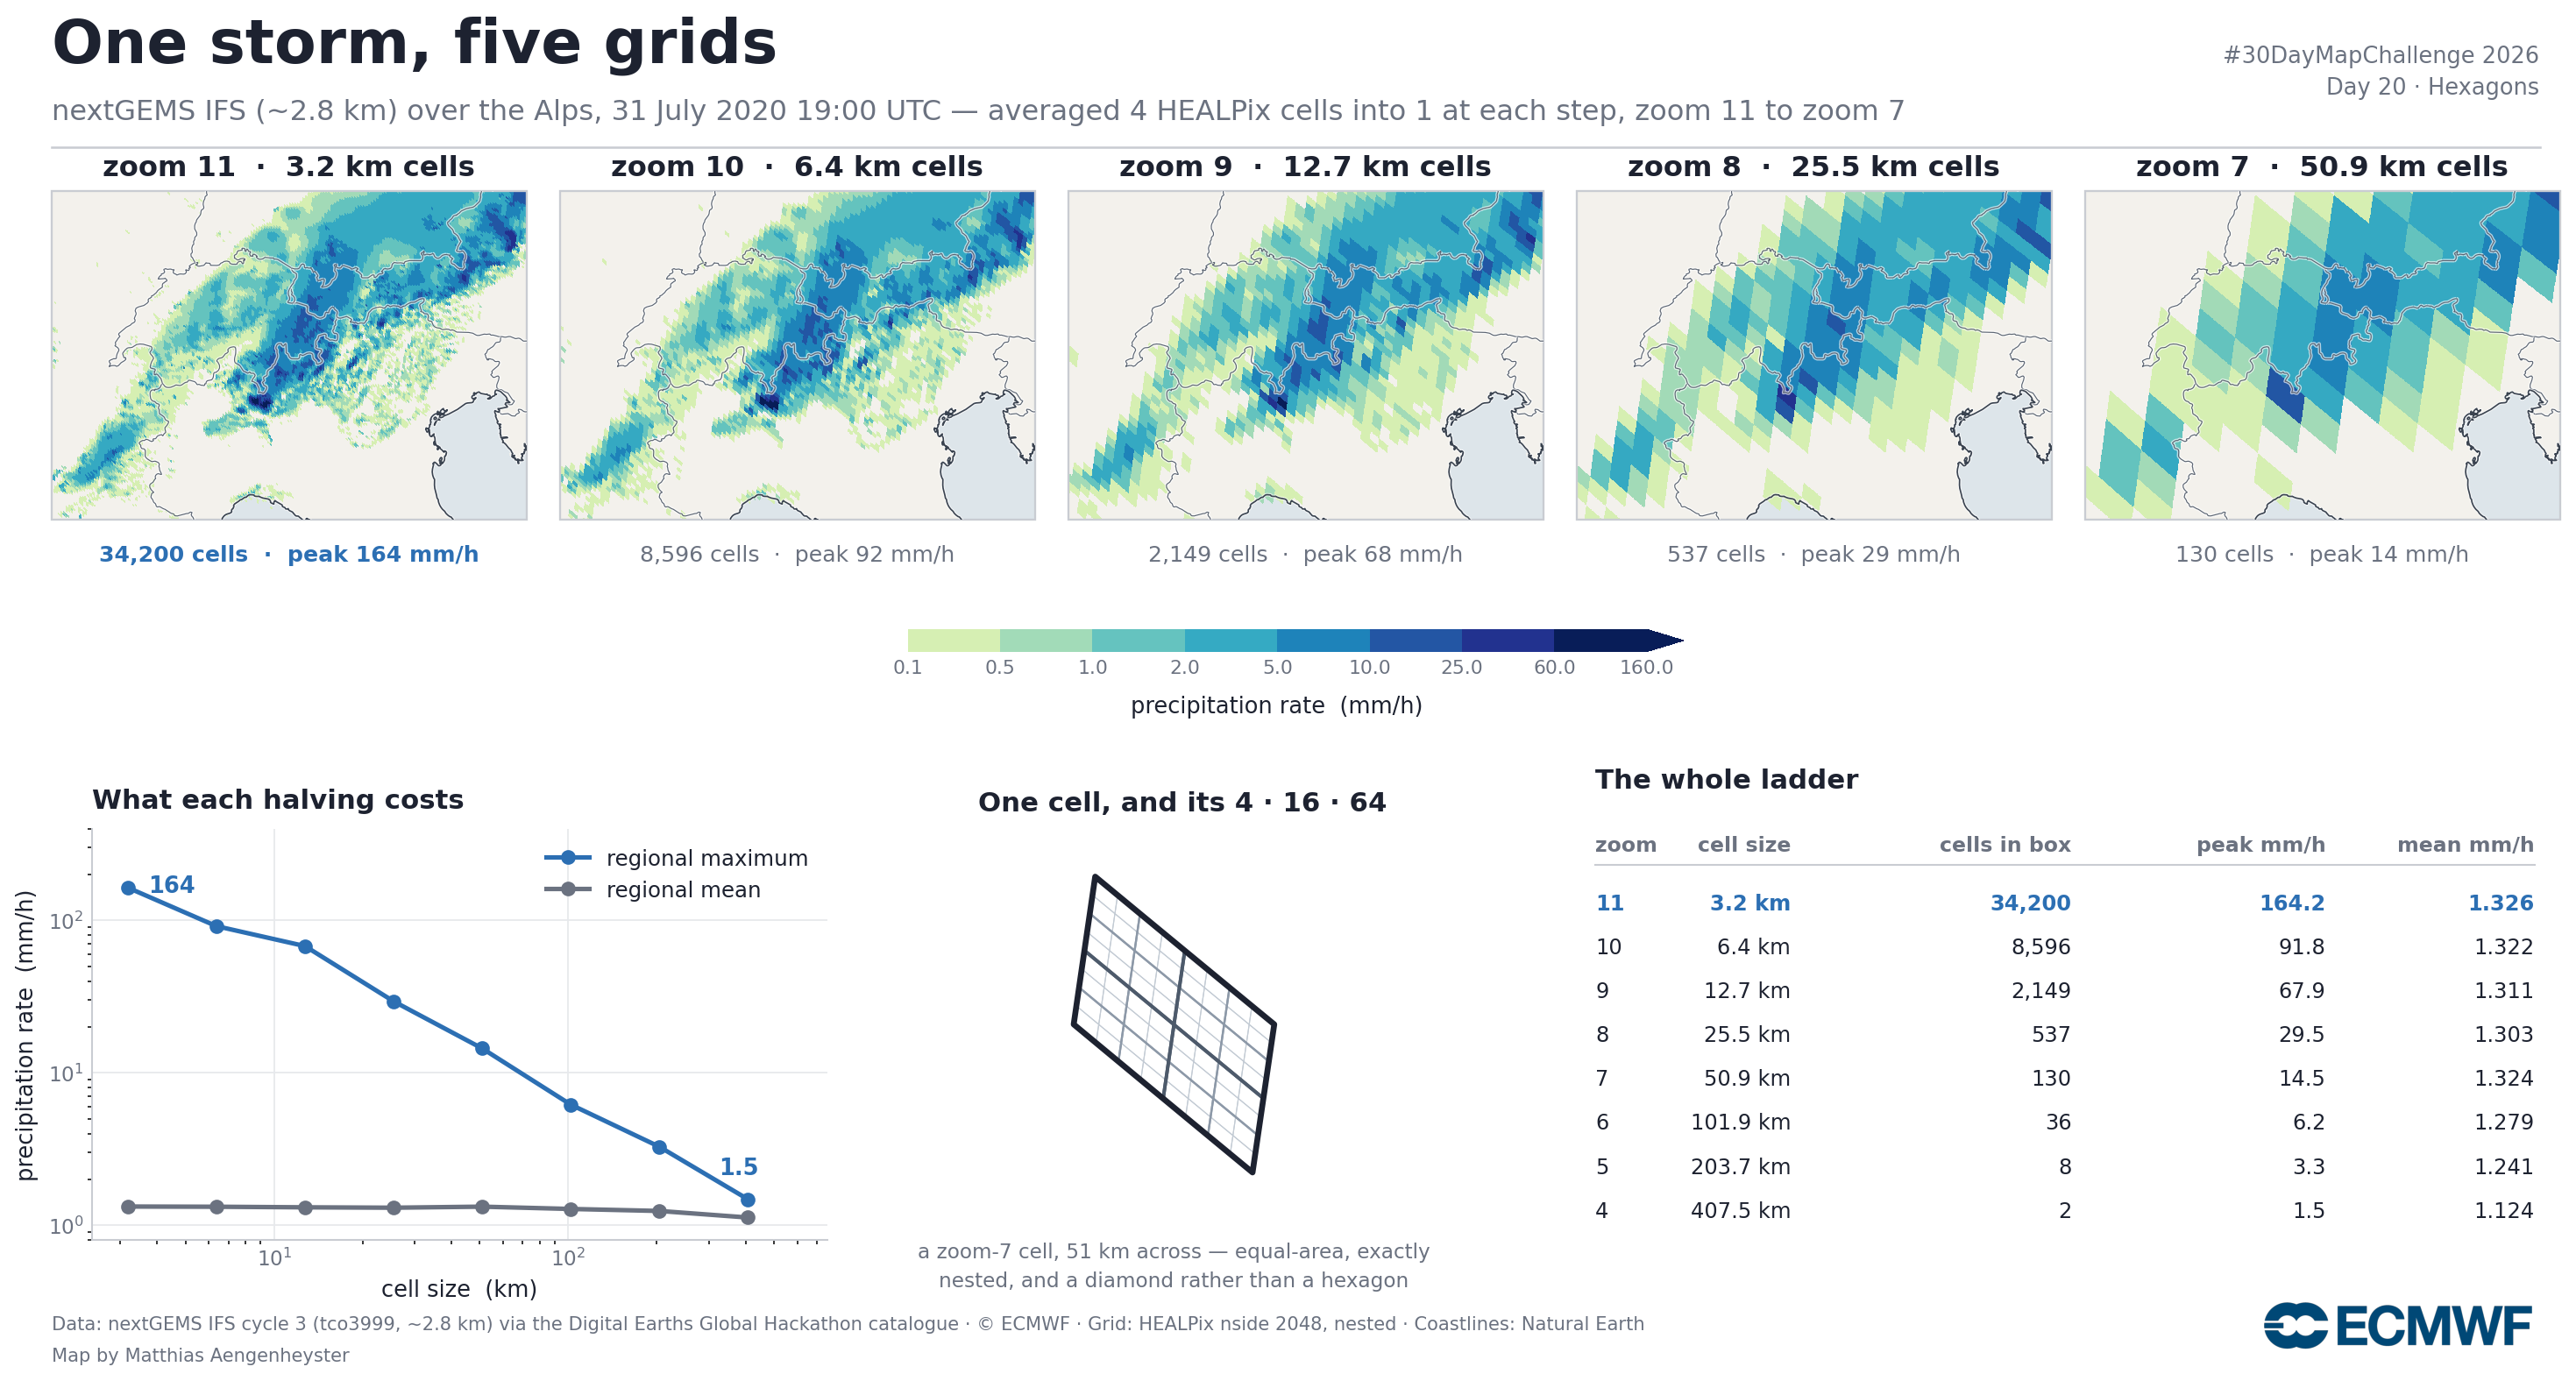

In [6]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PolyCollection

proj = ccrs.AlbersEqualArea(central_longitude=9.5, standard_parallels=(45, 48))

fig=plt.figure(figsize=(16.5,8.6),dpi=185); fig.patch.set_facecolor("white")
W,G,X0,Y0,H=0.1775,0.0125,0.035,0.620,0.245
for k,z in enumerate(ZOOMS):
    km,mx,mean,n=STAT[z]
    ax=fig.add_axes([X0+k*(W+G),Y0,W,H],projection=proj); basemap(ax,BOX)
    img,ext=raster(None,LAD[z],2**z,ax,nx=1500,ny=900); show(ax,img,ext)
    ax.set_title("zoom %d  ·  %.1f km cells"%(z,km),color=INK,fontsize=12.5,
                 fontweight="bold",pad=7)
    ax.text(0.5,-0.075,"%s cells  ·  peak %.0f mm/h"%(format(int(n),","),mx),
            transform=ax.transAxes,ha="center",va="top",
            color=ACC if z==11 else MUT,fontsize=9.8,
            fontweight="bold" if z==11 else "normal")

cax=fig.add_axes([0.355,0.530,0.29,0.016])
cb=fig.colorbar(ScalarMappable(norm=NORM,cmap=CMAP),cax=cax,orientation="horizontal",
                spacing="uniform",ticks=BINS,extend="max")
cb.set_label("precipitation rate  (mm/h)",color=INK,fontsize=10,labelpad=8)
cb.ax.tick_params(labelsize=8.5,colors=MUT,length=0); cb.outline.set_visible(False)

# ---------------------------------------------------------------- what it costs
ax2=fig.add_axes([0.050,0.108,0.275,0.295])
km=np.array([STAT[z][0] for z in ALL]); mx=np.array([STAT[z][1] for z in ALL])
mn=np.array([STAT[z][2] for z in ALL])
ax2.plot(km,mx,"-o",color=ACC,lw=2.0,ms=5.5,zorder=3,label="regional maximum")
ax2.plot(km,mn,"-o",color=MUT,lw=2.0,ms=5.5,zorder=3,label="regional mean")
ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlim(2.4,760); ax2.set_ylim(0.8,400)
ax2.set_xlabel("cell size  (km)",color=INK,fontsize=10)
ax2.set_ylabel("precipitation rate  (mm/h)",color=INK,fontsize=10)
ax2.grid(True,which="major",color="#e7e9ec",lw=0.7); ax2.set_axisbelow(True)
for s in ("top","right"): ax2.spines[s].set_visible(False)
for s in ("left","bottom"): ax2.spines[s].set_color(EDGE)
ax2.tick_params(colors=MUT,labelsize=9,length=0)
ax2.annotate("%.0f"%mx[0],(km[0],mx[0]),textcoords="offset points",xytext=(9,-2),
             color=ACC,fontsize=10,fontweight="bold")
ax2.annotate("%.1f"%mx[-1],(km[-1],mx[-1]),textcoords="offset points",xytext=(-4,11),
             color=ACC,fontsize=10,fontweight="bold",ha="center")
ax2.legend(frameon=False,fontsize=9.5,loc="upper right",labelcolor=INK)
ax2.set_title("What each halving costs",color=INK,fontsize=12,fontweight="bold",loc="left",pad=9)

# ---------------------------------------------------- what a HEALPix cell is
CEN=hp.ang2pix(128,9.5,46.5,nest=True,lonlat=True)
lo0,la0=hp.pix2ang(128,CEN,nest=True,lonlat=True)
gn=ccrs.Gnomonic(central_longitude=lo0,central_latitude=la0)
ax3=fig.add_axes([0.372,0.122,0.165,0.281],projection=gn)
r=5.8e4; ax3.set_xlim(-r,r); ax3.set_ylim(-r,r); ax3.set_facecolor("white")
def polys(z,pix):
    b=hp.boundaries(2**z,pix,step=12,nest=True)
    lo,la=hp.vec2ang(np.moveaxis(b,1,-1),lonlat=True)
    lo=np.where(lo>180,lo-360,lo)
    xy=gn.transform_points(PC,lo.ravel(),la.ravel())[:,:2]
    return xy.reshape(np.size(pix),-1,2)
for z,lw,col in ((10,0.45,"#c3cbd4"),(9,0.9,"#8d99a8"),(8,1.5,"#4d5a6b"),(7,2.6,INK)):
    kids=np.arange(CEN*4**(z-7),(CEN+1)*4**(z-7))
    ax3.add_collection(PolyCollection(polys(z,kids),facecolors="none",
                                      edgecolors=col,linewidths=lw,zorder=10-z+2))
ax3.set_title("One cell, and its 4 · 16 · 64",color=INK,fontsize=12,fontweight="bold",loc="left",pad=8)
for s in ax3.spines.values(): s.set_visible(False)
ax3.text(0.5,-0.055,"a zoom-7 cell, 51 km across — equal-area, exactly\n"
         "nested, and a diamond rather than a hexagon",
         transform=ax3.transAxes,ha="center",va="top",color=MUT,fontsize=9.0,linespacing=1.55)

# ---------------------------------------------------------------- the ladder
CX=[0.612,0.685,0.790,0.885,0.963]
fig.text(CX[0],0.432,"The whole ladder",color=INK,fontsize=12,fontweight="bold")
hd=["zoom","cell size","cells in box","peak mm/h","mean mm/h"]
for x,t,ha in zip(CX,hd,["left","right","right","right","right"]):
    fig.text(x,0.387,t,color=MUT,fontsize=9.2,fontweight="bold",ha=ha)
fig.lines.append(plt.Line2D([CX[0],CX[-1]],[0.377,0.377],transform=fig.transFigure,color=EDGE,lw=0.8))
for i,z in enumerate(ALL):
    y=0.345-i*0.0315
    c=ACC if z==11 else INK
    w="bold" if z==11 else "normal"
    km_,mx_,mn_,n_=STAT[z]
    for x,t,ha in zip(CX,["%d"%z,"%.1f km"%km_,format(int(n_),","),"%.1f"%mx_,"%.3f"%mn_],
                      ["left","right","right","right","right"]):
        fig.text(x,y,t,color=c,fontsize=9.4,ha=ha,fontweight=w)

fig.text(0.035,0.953,"One storm, five grids",color=INK,fontsize=27,fontweight="bold")
fig.text(0.035,0.912,"nextGEMS IFS (~2.8 km) over the Alps, 31 July 2020 19:00 UTC — averaged 4 HEALPix "
         "cells into 1 at each step, zoom 11 to zoom 7",color=MUT,fontsize=12.5)
fig.text(0.965,0.953,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.965,0.930,"Day 20 · Hexagons",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.035,0.965],[0.892,0.892],transform=fig.transFigure,color=EDGE,lw=1.0))
fig.text(0.035,0.044,"Data: nextGEMS IFS cycle 3 (tco3999, ~2.8 km) via the Digital Earths Global Hackathon "
         "catalogue · © ECMWF · Grid: HEALPix nside 2048, nested · Coastlines: Natural Earth",
         color=MUT,fontsize=8.2)
fig.text(0.035,0.021,"Map by Matthias Aengenheyster",
         color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.862,0.022,0.10,0.049]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day20_healpix_ladder.png",facecolor="white")
print("saved day20_healpix_ladder.png")

## The same ladder, on the operational projection

The run above is a one-year research experiment. **DestinE Climate DT** is the operational
km-scale projection, and it holds that resolution for decades rather than for one simulated
year. Its output is published on a **6.4 km HEALPix grid (zoom 10)** — the model itself runs
on its own native meshes, so zoom 10 is where the archive starts, not where the dynamics
happen. Five rungs down that ladder is a grid of roughly 200 km.

Nested indexing makes the read cheap. Pick the cells at the *bottom* of the ladder, expand
them to all their zoom-10 descendants, and those descendants occupy one short, contiguous
stretch of the index — 0.7% of the globe for central Europe — so a single slice of an 11 TB
store returns in well under a second.

Outside ECMWF the same field comes from **Polytope** with a DestinE account:

```python
from polytope.api import Client
Client(address="polytope.lumi.apps.dte.destination-earth.eu").retrieve("destination-earth", {
    "class": "d1", "dataset": "climate-dt", "activity": "baseline", "experiment": "hist",
    "model": "IFS-NEMO", "generation": "2", "realization": "1", "expver": "0001",
    "stream": "clte", "type": "fc", "levtype": "sfc", "param": "avg_tprate",
    "resolution": "high", "date": "20120910", "time": "0200",
}, "cdt_tprate.grib")
```

In [7]:
import xarray as xr

cdt = xr.open_zarr(CDT_ZARR, consolidated=False, decode_timedelta=False)
assert cdt["crs"].attrs["healpix_order"] == "nest", "store is not nested!"

base = box_pixels(2 ** CDT_ZC, *CDT_BOX)                 # coarsest rung first
pix  = descend(base, CDT_ZC, CDT_ZF)                     # ... and all its descendants
i0, i1 = int(pix.min()), int(pix.max()) + 1              # nested => one contiguous stretch
print(f"zoom {CDT_ZC}: {base.size} cells -> zoom {CDT_ZF}: {pix.size:,} cells, "
      f"read as {i1 - i0:,} contiguous ({100 * (i1 - i0) / cdt.sizes['value']:.1f}% of the globe)")

val = (cdt["avg_tprate"].sel(time=CDT_WHEN).isel(value=slice(i0, i1))
       .values[pix - i0] * 3600.0).astype("f4")

CLAD  = ladder(pix, val, CDT_ZF, CDT_ZC)
CSTAT = {}
for z, (p, v) in CLAD.items():
    lo, la = hp.pix2ang(2 ** z, p, nest=True, lonlat=True)
    lo = np.where(lo > 180, lo - 360, lo)
    m = ((lo > CDT_BOX[0]) & (lo < CDT_BOX[1]) & (la > CDT_BOX[2]) & (la < CDT_BOX[3]))
    CSTAT[z] = (cell_km(z), v[m].max(), v[m].mean(), m.sum())
    print(f"zoom {z:>2}  {CSTAT[z][0]:>6.1f} km  cells {m.sum():>6,}  "
          f"max {CSTAT[z][1]:>6.2f}  mean {CSTAT[z][2]:.4f}")

zoom 5: 52 cells -> zoom 10: 53,248 cells, read as 86,016 contiguous (0.7% of the globe)


zoom 10     6.4 km  cells 49,111  max  51.94  mean 0.5449
zoom  9    12.7 km  cells 12,288  max  46.50  mean 0.5469
zoom  8    25.5 km  cells  3,077  max  29.48  mean 0.5504
zoom  7    50.9 km  cells    761  max  18.55  mean 0.5475
zoom  6   101.9 km  cells    193  max   9.76  mean 0.5494
zoom  5   203.7 km  cells     52  max   6.69  mean 0.5251


## Figure 2 — the digital twin, five steps coarser

saved day20_healpix_climatedt.png


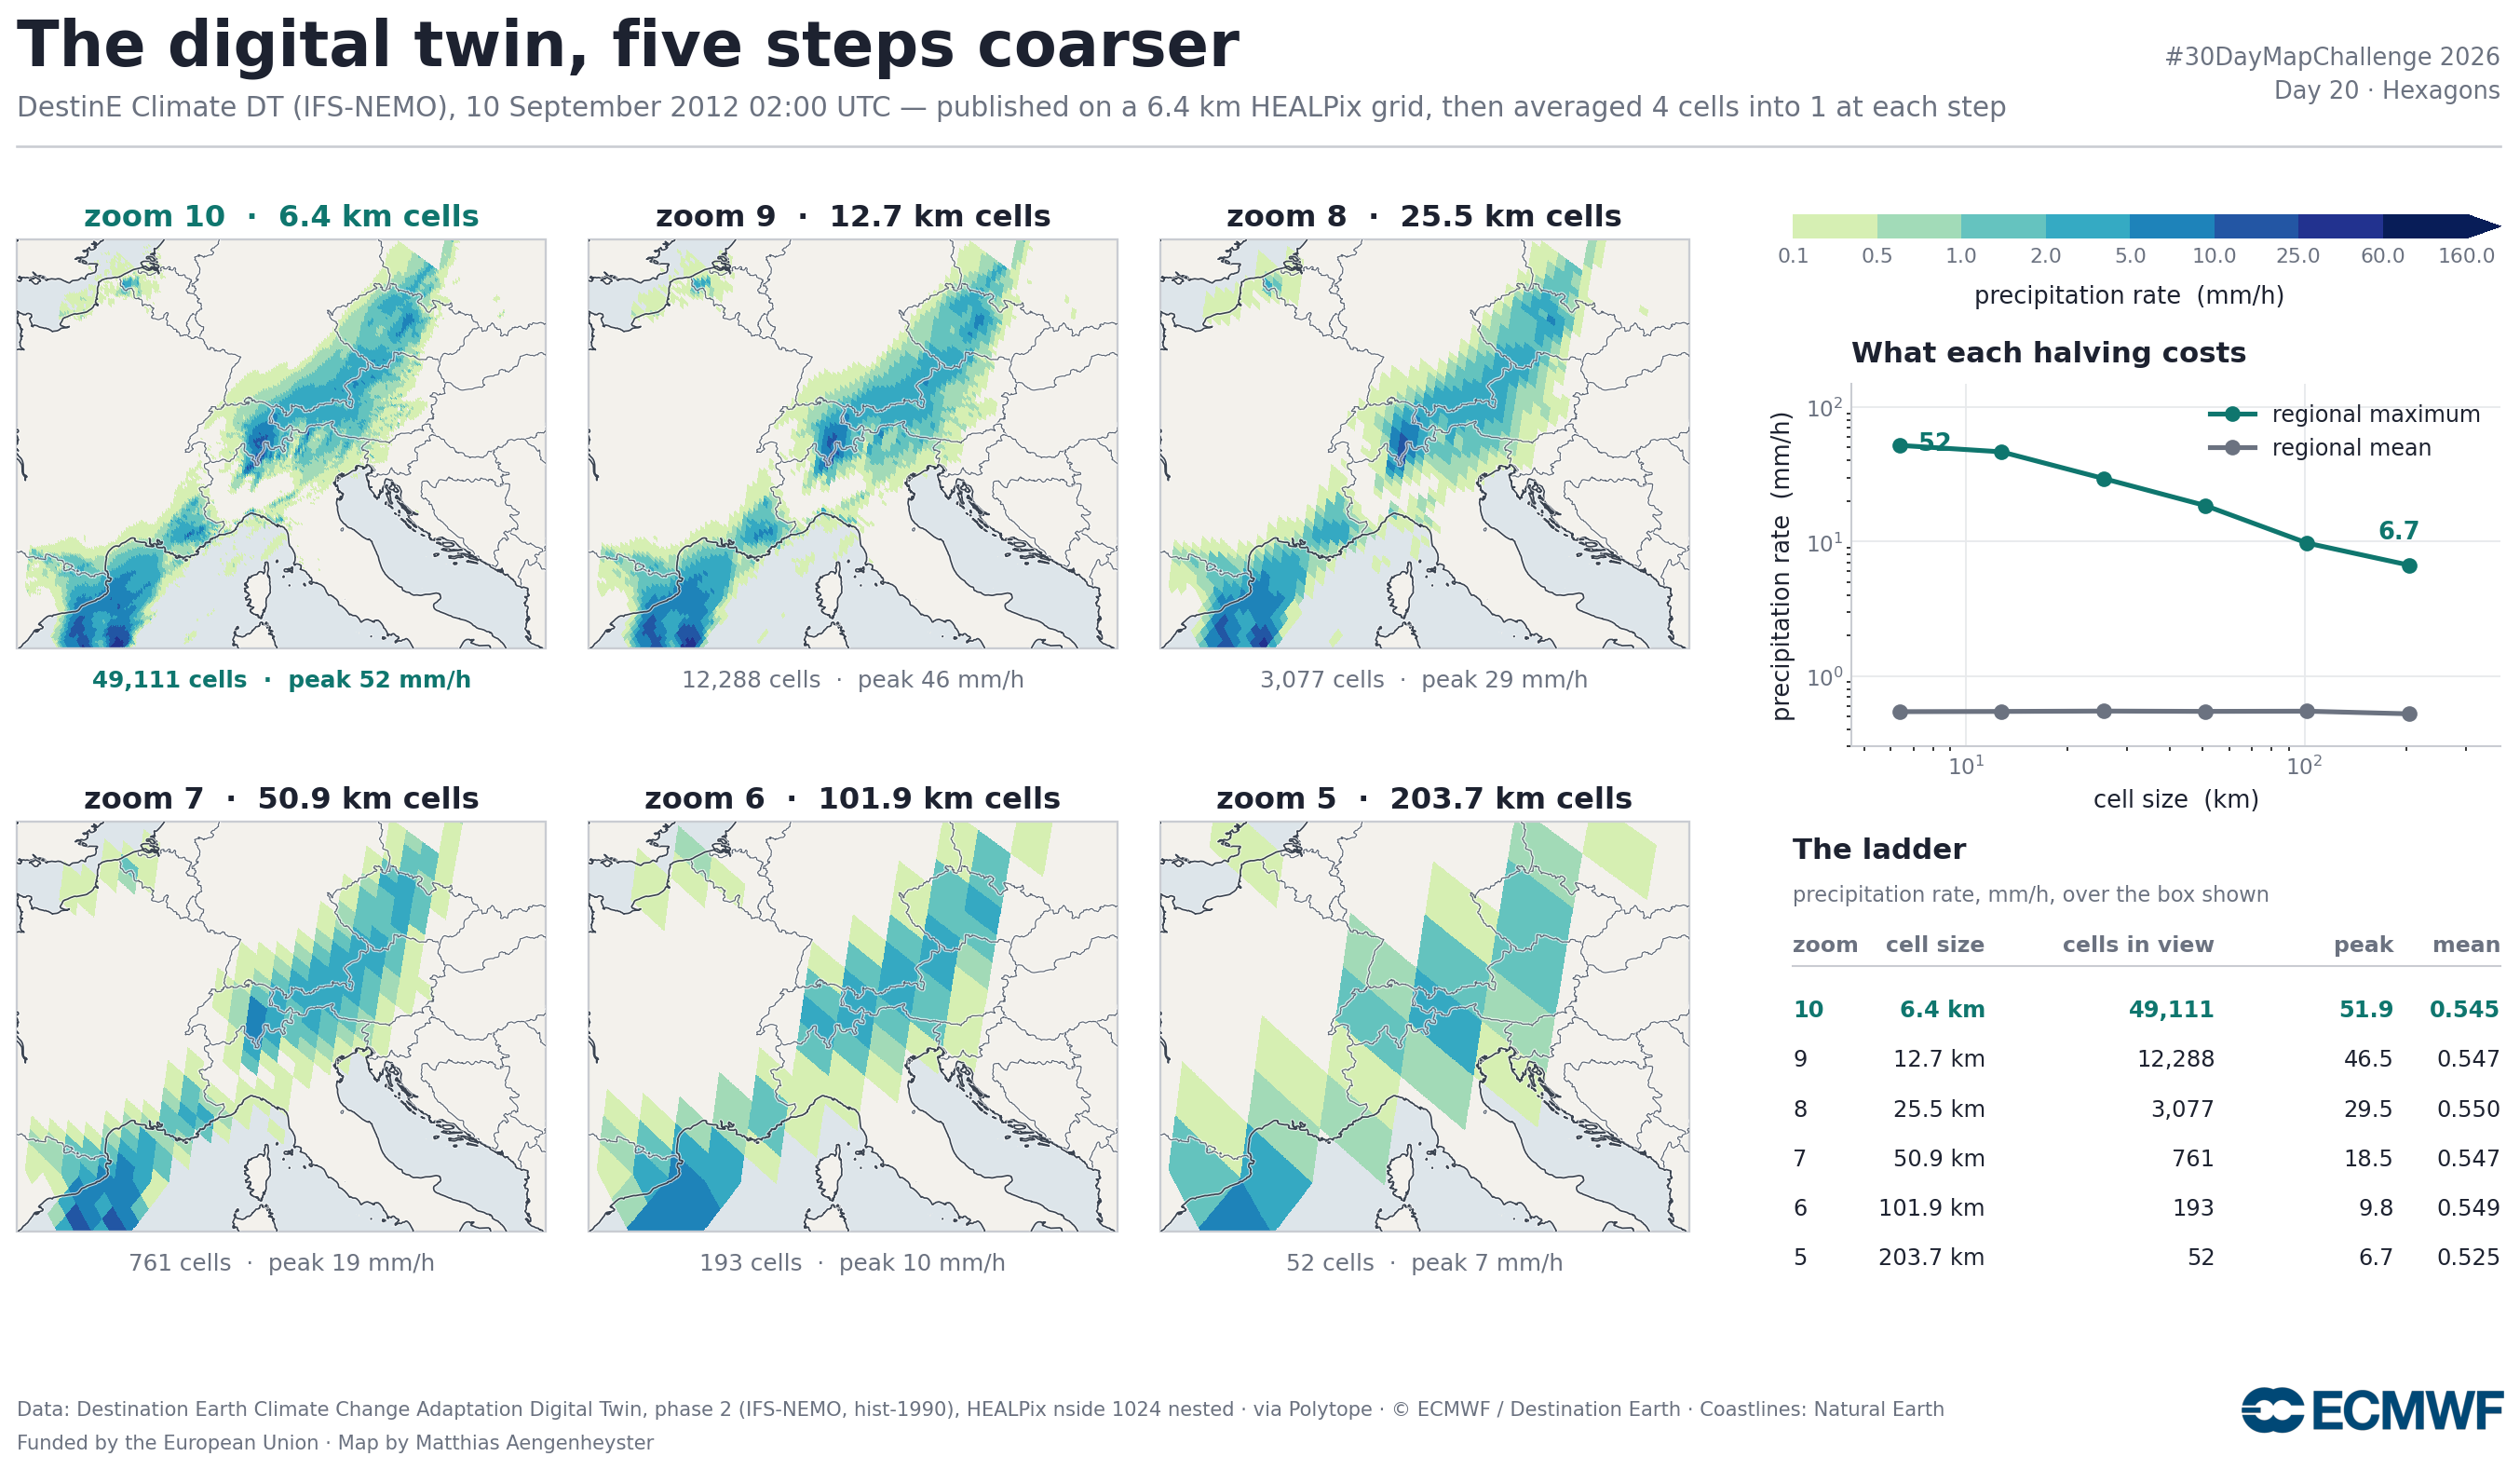

In [8]:
cproj = ccrs.AlbersEqualArea(central_longitude=10, standard_parallels=(43, 50))

fig=plt.figure(figsize=(15.5,8.6),dpi=185); fig.patch.set_facecolor("white")
W,HH,GX,GY,X0,Y1=0.198,0.308,0.016,0.085,0.035,0.545
for k,z in enumerate(range(CDT_ZF, CDT_ZC-1, -1)):
    r,c=divmod(k,3)
    ax=fig.add_axes([X0+c*(W+GX), Y1-r*(HH+GY), W, HH],projection=cproj)
    basemap(ax,CDT_BOX)
    img,ext=raster(CLAD[z][0],CLAD[z][1],2**z,ax,nx=1100,ny=750); show(ax,img,ext)
    km,mx,mean,n=CSTAT[z]
    ax.set_title("zoom %d  ·  %.1f km cells"%(z,km),color=CDT if z==CDT_ZF else INK,
                 fontsize=12.5,fontweight="bold",pad=6)
    ax.text(0.5,-0.050,"%s cells  ·  peak %.0f mm/h"%(format(int(n),","),mx),
            transform=ax.transAxes,ha="center",va="top",
            color=CDT if z==CDT_ZF else MUT,fontsize=9.6,
            fontweight="bold" if z==CDT_ZF else "normal")

cax=fig.add_axes([0.700,0.838,0.265,0.016])
cb=fig.colorbar(ScalarMappable(norm=NORM,cmap=CMAP),cax=cax,orientation="horizontal",
                spacing="uniform",ticks=BINS,extend="max")
cb.set_label("precipitation rate  (mm/h)",color=INK,fontsize=10,labelpad=8)
cb.ax.tick_params(labelsize=8.5,colors=MUT,length=0); cb.outline.set_visible(False)

zz=list(range(CDT_ZF, CDT_ZC-1, -1))
ax2=fig.add_axes([0.722,0.495,0.243,0.245])
km=np.array([CSTAT[z][0] for z in zz]); mx=np.array([CSTAT[z][1] for z in zz])
mn=np.array([CSTAT[z][2] for z in zz])
ax2.plot(km,mx,"-o",color=CDT,lw=2.0,ms=5.5,zorder=3,label="regional maximum")
ax2.plot(km,mn,"-o",color=MUT,lw=2.0,ms=5.5,zorder=3,label="regional mean")
ax2.set_xscale("log"); ax2.set_yscale("log"); ax2.set_xlim(4.6,380); ax2.set_ylim(0.30,150)
ax2.set_xlabel("cell size  (km)",color=INK,fontsize=10)
ax2.set_ylabel("precipitation rate  (mm/h)",color=INK,fontsize=10)
ax2.grid(True,which="major",color="#e7e9ec",lw=0.7); ax2.set_axisbelow(True)
for s in ("top","right"): ax2.spines[s].set_visible(False)
for s in ("left","bottom"): ax2.spines[s].set_color(EDGE)
ax2.tick_params(colors=MUT,labelsize=9,length=0)
ax2.annotate("%.0f"%mx[0],(km[0],mx[0]),textcoords="offset points",xytext=(8,-2),
             color=CDT,fontsize=10,fontweight="bold")
ax2.annotate("%.1f"%mx[-1],(km[-1],mx[-1]),textcoords="offset points",xytext=(-4,11),
             color=CDT,fontsize=10,fontweight="bold",ha="center")
ax2.legend(frameon=False,fontsize=9.3,loc="upper right",labelcolor=INK)
ax2.set_title("What each halving costs",color=INK,fontsize=12,fontweight="bold",loc="left",pad=9)

CX=[0.700,0.772,0.858,0.925,0.965]
fig.text(CX[0],0.420,"The ladder",color=INK,fontsize=12,fontweight="bold")
fig.text(CX[0],0.391,"precipitation rate, mm/h, over the box shown",color=MUT,fontsize=8.8)
hd=["zoom","cell size","cells in view","peak","mean"]
for x,t,ha in zip(CX,hd,["left","right","right","right","right"]):
    fig.text(x,0.357,t,color=MUT,fontsize=9.2,fontweight="bold",ha=ha)
fig.lines.append(plt.Line2D([CX[0],CX[-1]],[0.347,0.347],transform=fig.transFigure,color=EDGE,lw=0.8))
for i,z in enumerate(zz):
    y=0.313-i*0.0335
    col=CDT if z==CDT_ZF else INK; w="bold" if z==CDT_ZF else "normal"
    km_,mx_,mn_,n_=CSTAT[z]
    for x,t,ha in zip(CX,["%d"%z,"%.1f km"%km_,format(int(n_),","),"%.1f"%mx_,"%.3f"%mn_],
                      ["left","right","right","right","right"]):
        fig.text(x,y,t,color=col,fontsize=9.4,ha=ha,fontweight=w)

fig.text(0.035,0.955,"The digital twin, five steps coarser",color=INK,fontsize=26,fontweight="bold")
fig.text(0.035,0.921,"DestinE Climate DT (IFS-NEMO), 10 September 2012 02:00 UTC — published on a "
         "6.4 km HEALPix grid, then averaged 4 cells into 1 at each step",color=MUT,fontsize=11.5)
fig.text(0.965,0.955,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.965,0.933,"Day 20 · Hexagons",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.035,0.965],[0.900,0.900],transform=fig.transFigure,color=EDGE,lw=1.0))
fig.text(0.035,0.044,"Data: Destination Earth Climate Change Adaptation Digital Twin, phase 2 (IFS-NEMO, hist-1990), "
         "HEALPix nside 1024 nested · via Polytope · © ECMWF / Destination Earth · Coastlines: Natural Earth",
         color=MUT,fontsize=8.2)
fig.text(0.035,0.021,"Funded by the European Union · Map by Matthias Aengenheyster",color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.868,0.022,0.098,0.050]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day20_healpix_climatedt.png",facecolor="white")
print("saved day20_healpix_climatedt.png")

## And now, actual hexagons

HEALPix is the grid the models are archived on, but it is not hexagonal, and the theme is.
**H3** is — so the last figure bins the same Alpine field into H3 hexagons at resolutions 6, 5
and 4: roughly 6.5, 17 and 45 km across.

Worth knowing, though it is not drawn: this is a re-binning, not the exact aggregation of the
ladder above. A hexagon cannot be tiled by hexagons, so an H3 parent and its seven children
neither cover the same ground nor stay inside one another — H3's hierarchy approximates where
HEALPix's is exact. What hexagons buy in exchange is uniform adjacency: six neighbours, all the
same distance away, in every direction.

In [9]:
import h3

pix = box_pixels(NSIDE, *H3_PAD)
lo, la = hp.pix2ang(NSIDE, pix, nest=True, lonlat=True)
lo = np.where(lo > 180, lo - 360, lo)
vals = field[pix]
print(f"binning {pix.size:,} HEALPix cells into hexagons")

HID, HVAL, HCEN, HAREA = {}, {}, {}, {}
for r in H3_RES:
    ids = np.array([h3.latlng_to_cell(float(b), float(a), r) for a, b in zip(lo, la)])
    uniq, inv = np.unique(ids, return_inverse=True)
    HID[r]   = uniq
    HVAL[r]  = (np.bincount(inv, weights=vals.astype("f8"))
                / np.bincount(inv)).astype("f4")          # HEALPix cells are equal-area,
    HCEN[r]  = np.array([h3.cell_to_latlng(u) for u in uniq])   # so a plain mean is correct
    HAREA[r] = h3.average_hexagon_area(r, unit="km^2")
    print(f"res {r}: {uniq.size:>6,} hexagons  {HAREA[r]:>8.1f} km²  "
          f"{1.0746 * np.sqrt(HAREA[r]):>5.2f} km across  max {HVAL[r].max():>6.2f} mm/h")

binning 82,296 HEALPix cells into hexagons
res 6: 23,829 hexagons      36.1 km²   6.46 km across  max 107.57 mm/h


res 5:  3,497 hexagons     252.9 km²  17.09 km across  max  49.35 mm/h
res 4:    532 hexagons    1770.3 km²  45.21 km across  max  18.53 mm/h


## Figure 3 — the same storm in hexagons

res 6:  9778 hexagons in box, 6.46 km across, max 107.6, mean 1.338
res 5:  1395 hexagons in box, 17.09 km across, max 49.3, mean 1.343
res 4:   199 hexagons in box, 45.21 km across, max 18.5, mean 1.329


saved day20_hexagons_h3.png


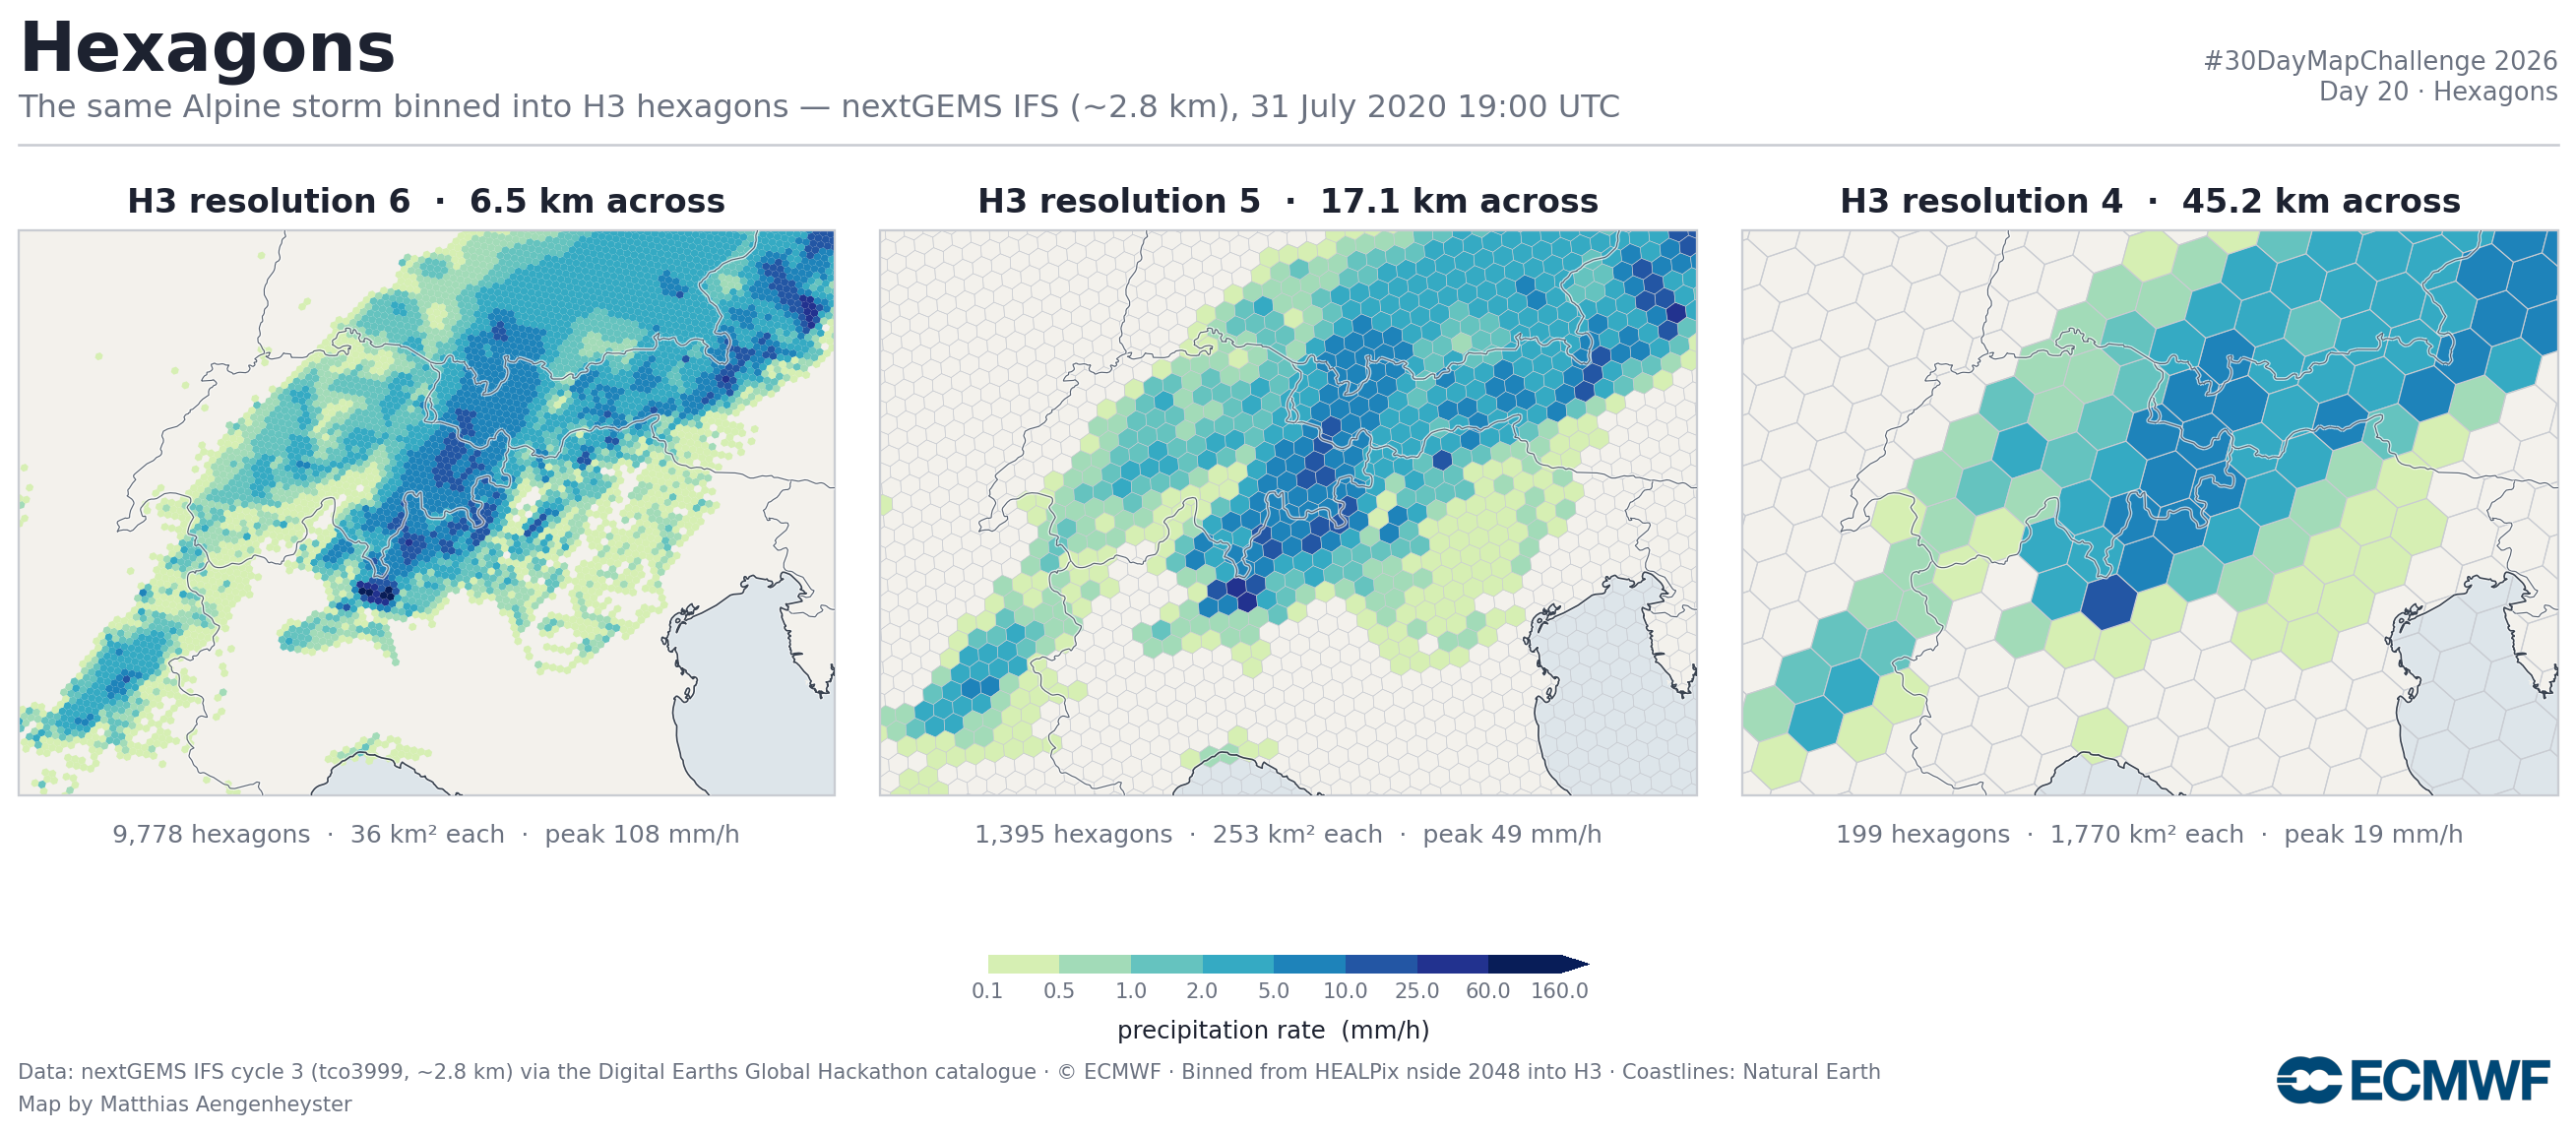

In [10]:
proj = ccrs.AlbersEqualArea(central_longitude=9.5, standard_parallels=(45, 48))

def hexes(ids, crs=None):
    """H3 cell boundaries, projected.  cell_to_boundary gives (lat, lon) pairs."""
    crs = crs or proj
    out=[]
    for c in ids:
        b=np.asarray(h3.cell_to_boundary(c))                     # (6 or 7, 2) lat,lon
        out.append(crs.transform_points(PC, b[:,1], b[:,0])[:,:2])
    return out

HST={}
for r in H3_RES:
    cen=HCEN[r]; v=HVAL[r]
    m=((cen[:,1]>BOX[0])&(cen[:,1]<BOX[1])&(cen[:,0]>BOX[2])&(cen[:,0]<BOX[3]))
    a=HAREA[r]
    HST[r]=(1.0746*np.sqrt(a), a, int(m.sum()), float(v[m].max()), float(v[m].mean()))
    print("res %d: %5d hexagons in box, %.2f km across, max %.1f, mean %.3f"%(
        r,m.sum(),HST[r][0],HST[r][3],HST[r][4]))

fig=plt.figure(figsize=(15.0,6.2),dpi=185); fig.patch.set_facecolor("white")
W,G,X0,Y0,HT=0.299,0.0165,0.035,0.300,0.520
for k,r in enumerate(H3_RES):
    ax=fig.add_axes([X0+k*(W+G),Y0,W,HT],projection=proj); basemap(ax,BOX)
    ids=HID[r]; v=HVAL[r]
    lw=0.0 if r==6 else (0.22 if r==5 else 0.45)
    ax.add_collection(PolyCollection(hexes(ids),array=np.where(v<BINS[0],np.nan,v),
                      cmap=CMAP,norm=NORM,edgecolors=EDGE if lw else "none",
                      linewidths=lw,zorder=2))
    across,area,n,mx,mn=HST[r]
    ax.set_title("H3 resolution %d  ·  %.1f km across"%(r,across),color=INK,
                 fontsize=13,fontweight="bold",pad=7)
    ax.text(0.5,-0.052,"%s hexagons  ·  %s km² each  ·  peak %.0f mm/h"%(
            format(n,","),format(int(round(area)),","),mx),
            transform=ax.transAxes,ha="center",va="top",color=MUT,fontsize=9.8)

cax=fig.add_axes([0.390,0.152,0.22,0.016])
cb=fig.colorbar(ScalarMappable(norm=NORM,cmap=CMAP),cax=cax,orientation="horizontal",
                spacing="uniform",ticks=BINS,extend="max")
cb.set_label("precipitation rate  (mm/h)",color=INK,fontsize=9.5,labelpad=7)
cb.ax.tick_params(labelsize=8.2,colors=MUT,length=0); cb.outline.set_visible(False)

fig.text(0.035,0.952,"Hexagons",color=INK,fontsize=27,fontweight="bold")
fig.text(0.035,0.910,"The same Alpine storm binned into H3 hexagons — nextGEMS IFS (~2.8 km), "
         "31 July 2020 19:00 UTC",color=MUT,fontsize=12.5)
fig.text(0.965,0.952,"#30DayMapChallenge 2026",color=MUT,fontsize=10,ha="right")
fig.text(0.965,0.925,"Day 20 · Hexagons",color=MUT,fontsize=10,ha="right")
fig.lines.append(plt.Line2D([0.035,0.965],[0.886,0.886],transform=fig.transFigure,color=EDGE,lw=1.0))
fig.text(0.035,0.058,"Data: nextGEMS IFS cycle 3 (tco3999, ~2.8 km) via the Digital Earths Global Hackathon "
         "catalogue · © ECMWF · Binned from HEALPix nside 2048 into H3 · Coastlines: Natural Earth",
         color=MUT,fontsize=8.2)
fig.text(0.035,0.030,"Map by Matthias Aengenheyster",
         color=MUT,fontsize=8.2)
try:
    a=fig.add_axes([0.862,0.028,0.10,0.058]); a.imshow(mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")); a.axis("off")
except FileNotFoundError: pass
fig.savefig("day20_hexagons_h3.png",facecolor="white")
print("saved day20_hexagons_h3.png")

## Note

The three resolution maps in this repo now say three different things. `day20_hexagons.ipynb`
compares **models**: ECMWF 25 km, ECMWF 9 km, MeteoSwiss 1 km, each on its own grid, which is
how resolution is usually shown and which always leaves the reader wondering how much of the
difference was the model rather than the mesh. This notebook compares **nothing but the mesh** —
same model, same hour, same field, one exact averaging operation repeated — and gets a factor
of 110 in the peak for it. [`day14_borgesian.ipynb`](day14_borgesian.ipynb) then holds the mesh
fixed and moves the frame instead, until one cell fills it.

One caveat the second figure states on its face: coarsening *output* is not the same as
running a coarse *model*. A 200 km model would not merely blur this field — it would never
generate it, because the storms that make it are smaller than its cells. That is the argument
for the twin, and it is why the panels are labelled as grids rather than as models.

Figures saved as `day20_healpix_ladder.png`, `day20_healpix_climatedt.png` and
`day20_hexagons_h3.png`.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and Copernicus) open data.*